In [2]:
import sys

print("Python location:", sys.executable)
print("Python version:", sys.version)

Python location: C:\Users\zhihe\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe
Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]


In [ ]:
import pandas as pd

print("pandas version:", pd.__version__)

pandas version: 3.0.6


In [5]:
from pathlib import Path

print("Current working folder:", Path.cwd())

Current working folder: c:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project


In [8]:
data_path = Path("data") / "raw" / "airfoil_self_noise.dat"

print("Dataset location:", data_path)
print("File found:", data_path.is_file())

Dataset location: data\raw\airfoil_self_noise.dat
File found: True


In [3]:
from pathlib import Path
import pandas as pd

data_path = Path("data") / "raw" / "airfoil_self_noise.dat"

column_names = [
    "frequency_hz",
    "angle_deg",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m",
    "scaled_spl_db"
]

data = pd.read_csv(
    data_path,
    sep=r"\s+",
    header=None,
    names=column_names
)

print("Dataset shape:", data.shape)

data.head(10)
X = data.drop(columns=["scaled_spl_db"])

y = data["scaled_spl_db"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Dataset shape: (1503, 6)
Input shape: (1503, 5)
Target shape: (1503,)


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.model_selection import cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

print("scikit-learn version:", sklearn.__version__)



scikit-learn version: 1.9.1


In [ ]:
#Confirm the input and output 
FEATURES = [
    "frequency_hz",
    "angle_deg",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m"
]

TARGET = "scaled_spl_db"

X = data[FEATURES].copy()
y = data[TARGET].copy()

print("Input shape:", X.shape)
print("Target shape:", y.shape)

group_columns = [
    "angle_deg",
    "chord_m",
    "velocity_m_s"
]

groups = X.groupby(group_columns, sort=True).ngroup()

print("Number of condition groups:", groups.nunique())

Input shape: (1503, 5)
Target shape: (1503,)
Number of condition groups: 106


In [ ]:
#Divide the complete dataset into development data and final test data

splitter = GroupShuffleSplit(
    n_splits=1, #Generate one development/test split
    test_size=0.20, #Reserve approximately 20% of groups
    random_state=SEED
)

dev_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()

X_test = X.iloc[test_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_dev = groups.iloc[dev_idx]
groups_test = groups.iloc[test_idx]

print("Development rows:", len(X_dev))
print("Final test rows:", len(X_test))

print("Development groups:", groups_dev.nunique())
print("Final test groups:", groups_test.nunique())

# Explore the development data and examine it's numerical summary
development_data = data.iloc[dev_idx].copy()

development_summary = development_data.describe().T

development_summary

Development rows: 1182
Final test rows: 321
Development groups: 84
Final test groups: 22


,count,mean,std,min,25%,50%,75%,max
frequency_hz,1182.0,2955.879865,3253.167568,200.000000,800.000000,1600.000000,4000.000000,20000.000000
angle_deg,1182.0,6.896362,6.060298,0.000000,2.000000,5.300000,12.300000,22.200000
chord_m,1182.0,0.131878,0.096196,0.025400,0.050800,0.101600,0.228600,0.304800
velocity_m_s,1182.0,51.520643,15.761609,31.700000,39.600000,55.500000,71.300000,71.300000
displacement_thickness_m,1182.0,0.010968,0.013634,0.000401,0.002663,0.004676,0.013025,0.058411
scaled_spl_db,1182.0,124.924754,6.911733,103.380000,120.244000,125.734000,130.071000,140.987000


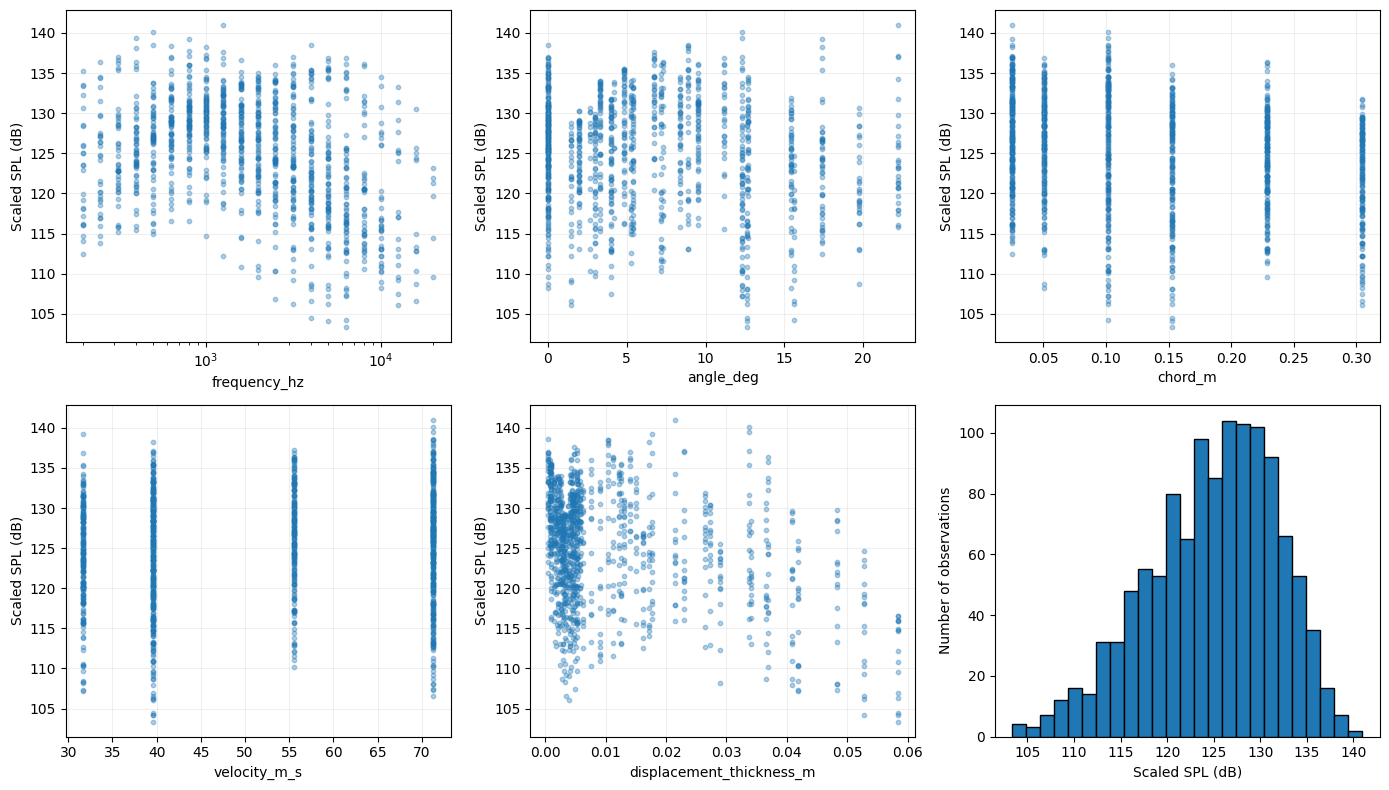

Number of folds: 5
Fold 1: 947 training rows, 235 validation rows
Fold 2: 947 training rows, 235 validation rows
Fold 3: 953 training rows, 229 validation rows
Fold 4: 934 training rows, 248 validation rows
Fold 5: 947 training rows, 235 validation rows


In [ ]:
# Create five scatter plot how each input relates to noise level, and one histogram showing the distribution of noise levels.
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, feature in zip(axes, FEATURES):
    ax.scatter(
        X_dev[feature],
        y_dev,
        s=10,
        alpha=0.35
    )

    ax.set_xlabel(feature)
    ax.set_ylabel("Scaled SPL (dB)")
    ax.grid(alpha=0.2)

    if feature == "frequency_hz":
        ax.set_xscale("log")

axes[5].hist(y_dev, bins=25, edgecolor="black")
axes[5].set_xlabel("Scaled SPL (dB)")
axes[5].set_ylabel("Number of observations")

fig.tight_layout()

fig.savefig(
    output_dir / "development_plots.png",
    dpi=200
)

plt.show()

#Create five validation folds within the development data.
cv = GroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

folds = list(
    cv.split(X_dev, y_dev, groups=groups_dev)
)

print("Number of folds:", len(folds))

for fold_number, (train_rows, val_rows) in enumerate(
    folds,
    start=1
):
    training_groups = set(groups_dev.iloc[train_rows])
    validation_groups = set(groups_dev.iloc[val_rows])

    assert training_groups.isdisjoint(validation_groups)

    print(
        f"Fold {fold_number}: "
        f"{len(train_rows)} training rows, "
        f"{len(val_rows)} validation rows"
    )

In [ ]:
#Define three initial model
models = {
    #Predicts the average target from its training rows for every new observation, it provides a minimum reference 
    "Mean": DummyRegressor(strategy="mean"),

    #Ridge fits a linear relationship with a penalty on large coefficient
    "Ridge": Pipeline([
        ("scale", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),
    
    #SVR with an RBF kernel can represent nonlinear relationships. Its main settings include:
    "SVR": Pipeline([
        ("scale", StandardScaler()),
        (
            "model",
            SVR(
                kernel="rbf",
                C=1.0,
                gamma="scale",
                epsilon=0.1
            )
        )
    ])
}

# Reusable evaluation function 
def evaluate_model(model, features, targets, cv_folds):
    """
    Evaluate a regression model on predefined validation folds.

    Parameters
    ----------
    model : scikit-learn estimator or Pipeline
        Model configuration to evaluate.
    features : pandas.DataFrame
        Numeric input features, with one observation per row.
    targets : pandas.Series
        Measured scaled SPL in dB, aligned with features.
    cv_folds : list of tuples
        Training and validation row positions within features.

    Returns
    -------
    pandas.DataFrame
        One row per fold: training RMSE, validation RMSE,
        validation MAE, validation R², and fitting time.
        Error metrics are in dB; fitting time is in seconds.
    """
    scores = cross_validate(
        model,
        features,
        targets,
        cv=cv_folds,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    return pd.DataFrame({
        "fold": np.arange(1, len(cv_folds) + 1),
        "train_rmse_db": -scores["train_rmse"],
        "val_rmse_db": -scores["test_rmse"],
        "val_mae_db": -scores["test_mae"],
        "val_r2": scores["test_r2"],
        "fit_time_s": scores["fit_time"]
    })

cv_tables = {}
comparison_rows = []

for name, model in models.items():
    fold_table = evaluate_model(
        model,
        X_dev,
        y_dev,
        folds
    )

    cv_tables[name] = fold_table

    comparison_rows.append({
        "model": name,
        "train_rmse_db": fold_table["train_rmse_db"].mean(),
        "cv_rmse_db": fold_table["val_rmse_db"].mean(),
        "fold_rmse_sd_db": fold_table["val_rmse_db"].std(ddof=1),
        "cv_mae_db": fold_table["val_mae_db"].mean(),
        "cv_r2": fold_table["val_r2"].mean(),
        "mean_fit_time_s": fold_table["fit_time_s"].mean()
    })

comparison = pd.DataFrame(comparison_rows)

comparison = comparison.sort_values("cv_rmse_db")

comparison.round(3)

,model,train_rmse_db,cv_rmse_db,fold_rmse_sd_db,cv_mae_db,cv_r2,mean_fit_time_s
2,SVR,3.772,4.035,0.353,3.049,0.645,0.027
1,Ridge,4.690,4.728,0.413,3.684,0.510,0.003
0,Mean,6.906,6.929,0.401,5.650,-0.020,0.001


1. If Ridge improves on the mean predictor, the inputs contain useful predictive information that a linear model can exploit.
2. If SVR improves further, a nonlinear model is a promising candidate.
3. A much smaller training error than validation error can indicate overfitting or difficulty transferring to excluded conditions.
4. High errors on both training and validation data may suggest an overly restrictive model, limited input information, or noisy observations.

In [27]:
cv_tables["Ridge"]

comparison.to_csv(
    output_dir / "baseline_comparison.csv",
    index=False
)

for name, fold_table in cv_tables.items():
    fold_table.to_csv(
        output_dir / f"{name.lower()}_cv_folds.csv",
        index=False
    )

development_summary.to_csv(
    output_dir / "development_summary.csv"
)

split_manifest = pd.DataFrame({
    "row_position": np.arange(len(data)),
    "group_id": groups.to_numpy(),
    "subset": "development"
})

split_manifest.loc[test_idx, "subset"] = "final_test"

split_manifest.to_csv(
    output_dir / "split_manifest.csv",
    index=False
)

In [10]:
# Prepare tools for tuning and confirm the existing development split.

from pathlib import Path
from time import perf_counter

import pandas as pd
from sklearn.model_selection import GridSearchCV

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

print("Development input shape:", X_dev.shape)
print("Number of validation folds:", len(folds))
print("Available models:", list(models.keys()))

Development input shape: (1182, 5)
Number of validation folds: 5
Available models: ['Mean', 'Ridge', 'SVR']


In [11]:
# Define candidate hyperparameters for Ridge and SVR.

ridge_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

svr_grid = {
    "model__C": [1.0, 10.0, 100.0],
    "model__gamma": ["scale", 0.05, 0.5],
    "model__epsilon": [0.1, 0.5]
}

In [12]:
# Find the Ridge penalty giving the lowest grouped validation RMSE.

ridge_search = GridSearchCV(
    estimator=models["Ridge"],
    param_grid=ridge_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

ridge_search.fit(X_dev, y_dev)

ridge_search_time = perf_counter() - start_time

print("Best Ridge settings:", ridge_search.best_params_)
print(
    "Best Ridge CV RMSE:",
    round(-ridge_search.best_score_, 3),
    "dB"
)
print(
    "Total Ridge search time:",
    round(ridge_search_time, 2),
    "seconds"
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Ridge settings: {'model__alpha': 10.0}
Best Ridge CV RMSE: 4.727 dB
Total Ridge search time: 0.17 seconds


In [13]:
# Find the SVR settings giving the lowest grouped validation RMSE.

svr_search = GridSearchCV(
    estimator=models["SVR"],
    param_grid=svr_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1
)

start_time = perf_counter()

svr_search.fit(X_dev, y_dev)

svr_search_time = perf_counter() - start_time

print("Best SVR settings:", svr_search.best_params_)
print(
    "Best SVR CV RMSE:",
    round(-svr_search.best_score_, 3),
    "dB"
)
print(
    "Total SVR search time:",
    round(svr_search_time, 2),
    "seconds"
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best SVR settings: {'model__C': 100.0, 'model__epsilon': 0.5, 'model__gamma': 0.5}
Best SVR CV RMSE: 3.477 dB
Total SVR search time: 10.29 seconds


In [14]:
# Compare baseline and tuned validation errors using identical folds.

baseline_rmse = comparison.set_index("model")["cv_rmse_db"]

tuning_summary = pd.DataFrame({
    "model": ["Ridge", "SVR"],

    "baseline_cv_rmse_db": [
        baseline_rmse["Ridge"],
        baseline_rmse["SVR"]
    ],

    "tuned_cv_rmse_db": [
        -ridge_search.best_score_,
        -svr_search.best_score_
    ],

    "search_time_s": [
        ridge_search_time,
        svr_search_time
    ]
})

tuning_summary["rmse_reduction_percent"] = (
    100
    * (
        tuning_summary["baseline_cv_rmse_db"]
        - tuning_summary["tuned_cv_rmse_db"]
    )
    / tuning_summary["baseline_cv_rmse_db"]
)

tuning_summary.round(3)

,model,baseline_cv_rmse_db,tuned_cv_rmse_db,search_time_s,rmse_reduction_percent
0,Ridge,4.728,4.727,0.166,0.013
1,SVR,4.035,3.477,10.289,13.840


In [16]:
# Inspect candidate training and validation errors to understand the search.

ridge_grid_results = pd.DataFrame(ridge_search.cv_results_)
svr_grid_results = pd.DataFrame(svr_search.cv_results_)

for table in [ridge_grid_results, svr_grid_results]:
    table["cv_rmse_db"] = -table["mean_test_score"]
    table["train_rmse_db"] = -table["mean_train_score"]

columns_to_show = [
    "param_model__C",
    "param_model__gamma",
    "param_model__epsilon",
    "train_rmse_db",
    "cv_rmse_db"
]

svr_grid_results.sort_values("cv_rmse_db")[
    columns_to_show
].head(5)

,param_model__C,param_model__gamma,param_model__epsilon,train_rmse_db,cv_rmse_db
17,100.0,0.5,0.5,2.150300,3.476731
11,10.0,0.5,0.5,2.604980,3.483926
14,100.0,0.5,0.1,2.168860,3.499447
8,10.0,0.5,0.1,2.616006,3.513519
9,10.0,scale,0.5,3.128913,3.599727


In [17]:
# Keep the tuned development models and save the search results.

tuned_models = {
    "Ridge": ridge_search.best_estimator_,
    "SVR": svr_search.best_estimator_
}

tuning_summary.to_csv(
    output_dir / "tuning_summary.csv",
    index=False
)

ridge_grid_results.to_csv(
    output_dir / "ridge_grid_search.csv",
    index=False
)

svr_grid_results.to_csv(
    output_dir / "svr_grid_search.csv",
    index=False
)

print("Tuned models available:", list(tuned_models.keys()))
print("Results saved in:", output_dir.resolve())

Tuned models available: ['Ridge', 'SVR']
Results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results


## Stage 2: Investigate preprocessing

In [18]:
# Prepare the preprocessing tools and check that the inputs selected for log10 are positive.

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

LOG_FEATURES = [
    "frequency_hz",
    "chord_m",
    "velocity_m_s",
    "displacement_thickness_m",
]

positive_inputs = X_dev[LOG_FEATURES].to_numpy(dtype=float)

if not np.isfinite(positive_inputs).all():
    raise ValueError(
        "The inputs selected for log10 contain missing or infinite values."
    )

if (positive_inputs <= 0).any():
    raise ValueError(
        "Every input selected for log10 must be greater than zero."
    )

print("Development data shape:", X_dev.shape)
print("Number of validation folds:", len(folds))
print("All inputs selected for log10 are finite and positive.")

Development data shape: (1182, 5)
Number of validation folds: 5
All inputs selected for log10 are finite and positive.


In [19]:
# Build pipelines that log selected inputs, scale all five inputs, and fit the model.

log_preprocessor = ColumnTransformer(
    transformers=[
        (
            "log10",
            FunctionTransformer(
                np.log10,
                validate=True,
                feature_names_out="one-to-one",
            ),
            LOG_FEATURES,
        ),
        (
            "angle",
            "passthrough",
            ["angle_deg"],
        ),
    ],
    remainder="drop",
)

log_ridge_pipeline = Pipeline(
    steps=[
        ("transform", clone(log_preprocessor)),
        ("scale", StandardScaler()),
        ("model", Ridge()),
    ]
)

log_svr_pipeline = Pipeline(
    steps=[
        ("transform", clone(log_preprocessor)),
        ("scale", StandardScaler()),
        ("model", SVR(kernel="rbf")),
    ]
)

print("Logarithmic preprocessing pipelines are ready.")

Logarithmic preprocessing pipelines are ready.


In [20]:
# Tune Ridge after logarithmic preprocessing using the original grid and validation folds.

log_ridge_search = GridSearchCV(
    estimator=log_ridge_pipeline,
    param_grid=ridge_search.param_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

log_ridge_search.fit(X_dev, y_dev)

print("Best log-preprocessed Ridge parameters:")
print(log_ridge_search.best_params_)

print(
    "Best log-preprocessed Ridge CV RMSE:",
    f"{-log_ridge_search.best_score_:.3f} dB",
)

Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best log-preprocessed Ridge parameters:
{'model__alpha': 10.0}
Best log-preprocessed Ridge CV RMSE: 5.217 dB


In [21]:
# Tune SVR after logarithmic preprocessing using the original grid and validation folds.

log_svr_search = GridSearchCV(
    estimator=log_svr_pipeline,
    param_grid=svr_search.param_grid,
    scoring="neg_root_mean_squared_error",
    cv=folds,
    refit=True,
    return_train_score=True,
    n_jobs=1,
    error_score="raise",
    verbose=1,
)

log_svr_search.fit(X_dev, y_dev)

print("Best log-preprocessed SVR parameters:")
print(log_svr_search.best_params_)

print(
    "Best log-preprocessed SVR CV RMSE:",
    f"{-log_svr_search.best_score_:.3f} dB",
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Best log-preprocessed SVR parameters:
{'model__C': 100.0, 'model__epsilon': 0.5, 'model__gamma': 0.05}
Best log-preprocessed SVR CV RMSE: 2.829 dB


In [22]:
# Compare tuned validation RMSE before and after logarithmic preprocessing.

preprocessing_comparison = pd.DataFrame(
    {
        "model": ["Ridge", "SVR"],
        "scaled_cv_rmse_db": [
            -ridge_search.best_score_,
            -svr_search.best_score_,
        ],
        "log_scaled_cv_rmse_db": [
            -log_ridge_search.best_score_,
            -log_svr_search.best_score_,
        ],
    }
)

preprocessing_comparison["rmse_reduction_db"] = (
    preprocessing_comparison["scaled_cv_rmse_db"]
    - preprocessing_comparison["log_scaled_cv_rmse_db"]
)

preprocessing_comparison.round(3)

,model,scaled_cv_rmse_db,log_scaled_cv_rmse_db,rmse_reduction_db
0,Ridge,4.727,5.217,-0.490
1,SVR,3.477,2.829,0.648


In [26]:
# Inspect training and validation errors for the logarithmically preprocessed searches.

log_ridge_results = pd.DataFrame(log_ridge_search.cv_results_)
log_svr_results = pd.DataFrame(log_svr_search.cv_results_)

for table in [log_ridge_results, log_svr_results]:
    table["cv_rmse_db"] = -table["mean_test_score"]
    table["train_rmse_db"] = -table["mean_train_score"]

columns_to_show = [
    "param_model__C",
    "param_model__gamma",
    "param_model__epsilon",
    "train_rmse_db",
    "cv_rmse_db",
]

log_svr_results.sort_values("cv_rmse_db")[columns_to_show].head(5)

,param_model__C,param_model__gamma,param_model__epsilon,train_rmse_db,cv_rmse_db
16,100.0,0.05,0.5,2.360238,2.828992
8,10.0,0.5,0.1,1.533498,2.843152
6,10.0,scale,0.1,2.079920,2.853051
9,10.0,scale,0.5,2.066597,2.853399
11,10.0,0.5,0.5,1.519170,2.855327


In [25]:
# Save the preprocessing evidence and retain all four fitted candidate pipelines.

preprocessing_candidates = {
    "Ridge_scaled": ridge_search.best_estimator_,
    "Ridge_log_scaled": log_ridge_search.best_estimator_,
    "SVR_scaled": svr_search.best_estimator_,
    "SVR_log_scaled": log_svr_search.best_estimator_,
}

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

preprocessing_comparison.to_csv(
    output_dir / "preprocessing_comparison.csv",
    index=False,
)

log_ridge_results.to_csv(
    output_dir / "ridge_log_grid_search.csv",
    index=False,
)

log_svr_results.to_csv(
    output_dir / "svr_log_grid_search.csv",
    index=False,
)

print("Results saved in:", output_dir.resolve())
print("Available candidates:", list(preprocessing_candidates))

Results saved in: C:\Monash\Year 3 Sem 1\MMA3001\MMA3001-Final-Project\results
Available candidates: ['Ridge_scaled', 'Ridge_log_scaled', 'SVR_scaled', 'SVR_log_scaled']
